In [90]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import datetime

1 Ignition On
2 Ignition oFf
3 Drive
4 Idle stop
5 Parked
6 Power On
7 Ping
8 Travel start
9 Travel stop
45 Idle Alert
33 Tow
65 Acceleration
66 Hard brake
53 Hard turn
38 Consistent speed
34 End Speeding

In [91]:
#unit=pd.read_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\zona_logistica\esp840_1620_02_2026.csv',sep=',') #for csv files.
unit=pd.read_excel(r'C:\Users\Jose.Hurtado\Downloads\raw-data_WHI316_2026-11-01_2026-11-27.xlsx') #For xls files.
unit.info()

<class 'pandas.DataFrame'>
RangeIndex: 13720 entries, 0 to 13719
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Created    13720 non-null  str    
 1   Message    13720 non-null  str    
 2   Status     13720 non-null  str    
 3   Type       0 non-null      float64
 4   Alarm      0 non-null      float64
 5   Ignition   0 non-null      float64
 6   Latitude   0 non-null      float64
 7   Longitude  0 non-null      float64
 8   Speed      0 non-null      float64
dtypes: float64(6), str(3)
memory usage: 964.8 KB


In [92]:
date=[]
for i in range(0,unit.shape[0]):
    date.append(int(unit.iloc[i,2][28:36],16))

unit['Date epoch']=date

unit=unit.sort_values('Date epoch',ascending=True)

unit.head(5)

,Created,Message,Status,Type,Alarm,Ignition,Latitude,Longitude,Speed,Date epoch
13719,2026-11-01 00:00:13.400,"11000001,5,4764400477,1,1,1,10,7,1793491211,10...",0x830547644004770101010A00076AE6810B067FDA66D3...,NaN,NaN,NaN,NaN,NaN,NaN,1793491211
13718,2026-11-01 00:00:14.695,"11000001,5,4764400477,1,1,1,10,8,1793491214,10...",0x830547644004770101010A00086AE6810E067FDE92D3...,NaN,NaN,NaN,NaN,NaN,NaN,1793491214
13717,2026-11-01 00:01:03.842,"11000001,5,4764400477,1,1,1,10,9,1793491262,10...",0x830547644004770101010A00096AE6813E0680600DD3...,NaN,NaN,NaN,NaN,NaN,NaN,1793491262
13716,2026-11-01 00:01:08.099,"11000001,5,4764400477,1,1,1,10,10,1793491267,1...",0x830547644004770101010A000A6AE6814306805EB2D3...,NaN,NaN,NaN,NaN,NaN,NaN,1793491267
13715,2026-11-01 00:02:20.128,"11000001,5,4764400477,1,1,1,10,11,1793491339,1...",0x830547644004770101010A000B6AE6818B06801EA2D3...,NaN,NaN,NaN,NaN,NaN,NaN,1793491339


Odometer

       Odometer in  Odometer en miles
0         25336338       15743.265679
1         25336349       15743.272514
2         25336763       15743.529762
3         25336804       15743.555238
4         25337406       15743.929304
...            ...                ...
13715     29693400       18450.617651
13716     29693967       18450.969969
13717     29693973       18450.973697
13718     29694174       18451.098593
13719     29694520       18451.313587

[13720 rows x 2 columns]


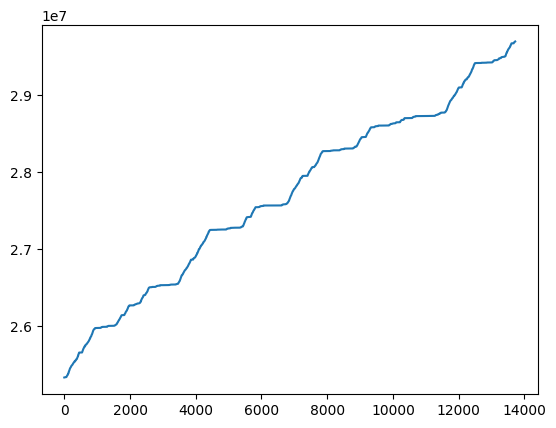

In [93]:
aux=[]
aux_miles=[]
x_axis=[]
unit_odometer=pd.DataFrame()
cont=0

for i in range (0,unit.shape[0]):
    l=len(unit.iloc[i,2])
    #print('Len=',l)
    if l<180:
        aux.append(int(unit.iloc[i,2][68:76],16))
        aux_miles.append((int(unit.iloc[i,2][68:76],16))*0.000621371)
        cont=cont+1     

unit_odometer['Odometer in']=aux
unit_odometer['Odometer en miles']=aux_miles

for i in range(0,cont):
    x_axis.append(i)

print(unit_odometer)
unit_odometer
plt.plot(x_axis,aux)

Harsh turn

Event codes only for No User messages.
Harsh Turn: 35 on Hex, 53 on Dec

In [94]:
event_code=[]

for i in range(0,unit.shape[0]):
    event_code.append(unit.iloc[i,2][64:68])
    if unit.iloc[i,2][64:66]=='35': # Put the Even Code to look for.
        print(unit.iloc[i,2][64:66],' -> ',unit.iloc[i,0])

35  ->  2026-11-01 05:01:38.252
35  ->  2026-11-01 07:10:03.136
35  ->  2026-11-01 18:36:07.799
35  ->  2026-11-03 22:53:20.130
35  ->  2026-11-03 22:53:28.474
35  ->  2026-11-03 22:53:29.290
35  ->  2026-11-07 07:00:10.614
35  ->  2026-11-07 08:28:46.437
35  ->  2026-11-07 16:50:44.689
35  ->  2026-11-07 20:36:14.010
35  ->  2026-11-07 20:36:14.443
35  ->  2026-11-07 20:37:04.144
35  ->  2026-11-07 20:43:11.949
35  ->  2026-11-07 21:34:39.552
35  ->  2026-11-07 21:34:40.003
35  ->  2026-11-07 21:37:10.896
35  ->  2026-11-07 22:03:54.527
35  ->  2026-11-11 01:31:29.780
35  ->  2026-11-11 02:06:01.971
35  ->  2026-11-14 19:52:10.478
35  ->  2026-11-14 19:54:11.385
35  ->  2026-11-14 20:02:08.989
35  ->  2026-11-14 20:01:41.186
35  ->  2026-11-14 20:08:01.700
35  ->  2026-11-14 20:08:03.960
35  ->  2026-11-14 20:37:54.502
35  ->  2026-11-14 20:37:54.057
35  ->  2026-11-14 22:22:05.941
35  ->  2026-11-16 11:02:58.032
35  ->  2026-11-16 11:03:13.354
35  ->  2026-11-17 17:40:03.312
35  ->  

Satellite number

In [95]:
cont=0
for i in range(0,unit.shape[0]):
    l=len(unit.iloc[i,2])
    if l>92:
        sn=int(unit.iloc[i,2][82:84],16)        
        if sn<5:
            print(unit.iloc[i,0], ' -> ',sn)
            cont=cont+1
    if l<93:
        sn=int(unit.iloc[i,2][55:57],16)        
        if sn<5:
            print(unit.iloc[i,0], ' -> ',sn)
            cont=cont+1

print('Messages with satellite number < 5: ',cont)
        

Messages with satellite number < 5:  0


Temperature

In [96]:
accum3=300#float(input('Type Accum 3 value: '))
celsius_temp=accum3*0.0625
farenheit_temp=(celsius_temp*9)/5+32
print('Celsius: ',celsius_temp,'farenheit: ',farenheit_temp)

Celsius:  18.75 farenheit:  65.75


In [97]:
aux_temp=[]
for i in range(0,unit.shape[0]):
    try:
        aux_temp.append(float(int(unit.iloc[i,2][96:100],16)*0.0625))
    except:
        pass
aux_temp

[999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,
 999.0,


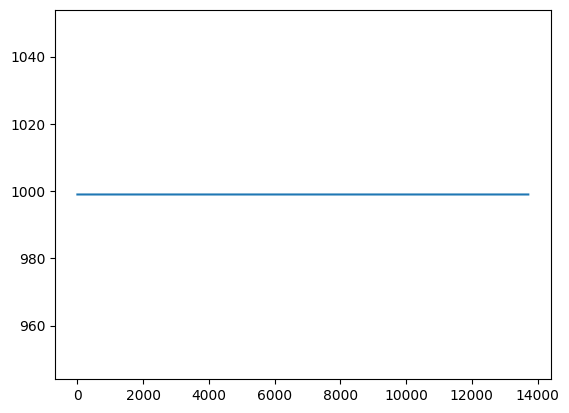

In [98]:
x_temp=[]
for i in range(0,len(aux_temp)):
    x_temp.append(i)

plt.plot(x_temp,aux_temp)

iButton

In [99]:
aux_temp=[]
for i in range(0,unit.shape[0]):    
    aux_temp.append(unit.iloc[i,2][108:124])
aux_temp

['',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',


Binary inputs

In [100]:
for i in range(0,unit.shape[0]):   
    if unit.iloc[i,2][64:66]=='0C': # Put the Even Code to look for.
        cont=cont+1
        print(bin(int(unit.iloc[i,2][62:64],16)),' -> ',unit.iloc[i,0])
print("Total event codes 0C input2 Off: ",cont)

Total event codes 0C input2 Off:  0


In [101]:
sequence=[]
sequence.append(unit.iloc[0,2][24:28])
sequence

['0007']

[10, 17, 22, 35, 9, 9, 32, 13, 24, 24, 25, 23, 27, 26, 29, 13, 11, 8, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 27, 10, 10, 24, 0, 44, 0, 26, 1, 26, 8, 0, 0, 1, 1, 1, 11, 0, 11, 0, 23, 43, 44, 46, 14, 48, 35, 9, 14, 75, 73, 86, 54, 77, 54, 38, 47, 27, 27, 39, 76, 71, 64, 33, 60, 75, 80, 44, 12, 0, 1, 43, 44, 79, 63, 78, 71, 61, 61, 61, 61, 61, 61, 85, 63, 37, 75, 81, 71, 66, 0, 17, 19, 76, 81, 83, 84, 86, 85, 50, 74, 77, 78, 55, 70, 76, 79, 79, 82, 82, 79, 47, 77, 79, 59, 80, 90, 53, 19, 61, 73, 79, 84, 83, 57, 69, 17, 35, 75, 75, 78, 57, 57, 68, 68, 80, 90, 83, 91, 91, 87, 89, 92, 87, 89, 73, 80, 76, 65, 15, 15, 49, 59, 74, 71, 67, 62, 62, 76, 68, 66, 76, 64, 56, 60, 84, 65, 61, 39, 90, 56, 22, 76, 75, 75, 75, 79, 66, 78, 58, 61, 69, 76, 82, 47, 12, 68, 76, 58, 87, 60, 60, 74, 66, 55, 70, 80, 71, 59, 46, 45, 59, 84, 59, 62, 64, 74, 23, 82, 82, 82, 82, 82, 82, 82, 69, 51, 78, 80, 64, 41, 20, 18, 77, 58, 58, 58, 71, 76, 75, 63, 53, 67, 67, 30

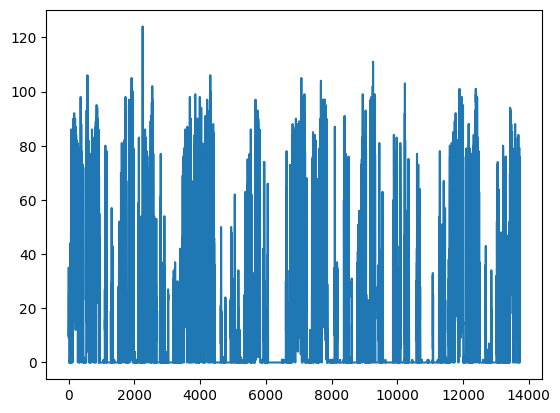

In [102]:
#Speed reported from Calamp untis is in Km/h, do not confuse, Decoded field pass the Speed in Km/h to mph, but the data is sent to CLoud in Km/H
aux=[]
aux_kmh=[]
x_axis=[]
unit_speed=pd.DataFrame()
cont=0

for i in range (0,unit.shape[0]):
    l=len(unit.iloc[i,2])
    #print('Len=',l)
    if l<180:
        aux.append(int(unit.iloc[i,2][56:58],16))
        #aux_kmh.append((int(unit.iloc[i,2][68:76],16))*0.036)
        cont=cont+1     

unit_speed['Speed Km-h']=aux
#unit_speed['Speed m-s']=aux_kmh

for i in range(0,cont):
    x_axis.append(i)

print(aux,cont)

plt.plot(x_axis,aux)

Idle alert:

In [103]:
idle_alert_events=pd.DataFrame()

event_code=[]
date_event_code=[]

for i in range(0,unit.shape[0]):
    #event_code.append(unit.iloc[i,2][64:68])
    if unit.iloc[i,2][64:66]=='2D': # Put the Even Code to look for.
        event_code.append(unit.iloc[i,2][64:66])
        date_event_code.append(unit.iloc[i,0])
        #print(unit.iloc[i,2][64:66],' -> ',unit.iloc[i,0])


idle_alert_events['Date']=date_event_code
idle_alert_events['Event']=event_code

print(idle_alert_events)

                         Date Event
0     2026-11-01 00:36:45.228    2D
1     2026-11-01 00:39:45.216    2D
2     2026-11-01 00:41:45.215    2D
3     2026-11-01 00:47:11.582    2D
4     2026-11-01 00:52:26.078    2D
...                       ...   ...
1694  2026-11-27 06:07:04.985    2D
1695  2026-11-27 06:07:05.384    2D
1696  2026-11-27 06:13:40.441    2D
1697  2026-11-27 06:13:40.945    2D
1698  2026-11-27 13:33:17.940    2D

[1699 rows x 2 columns]


Ignition on:

In [104]:
ignition_on=pd.DataFrame()
event_code=[]
date_event_code=[]
date_real_code=[]
hex_epoch=[]
var_epoch=[]

for i in range(0,unit.shape[0]):
    #event_code.append(unit.iloc[i,2][64:68])
    if unit.iloc[i,2][64:66]=='01': # Put the Even Code to look for.
        event_code.append(unit.iloc[i,2][64:66])
        date_event_code.append(unit.iloc[i,0])
        var_dec=int(unit.iloc[i,2][28:36],16)
        var_epoch.append(var_dec)
        aux_date=datetime.datetime.fromtimestamp(var_dec)
        date_real_code.append(aux_date)
        hex_epoch.append(unit.iloc[i,2][28:36])
        #print(unit.iloc[i,2][64:66],' -> ',unit.iloc[i,0])


ignition_on['Receive_Date']=date_event_code
ignition_on['Event']=event_code
ignition_on['Date_real_Event']=date_real_code
ignition_on['Epoch']=var_epoch
#ignition_on['hex_epoch']=hex_epoch

print(ignition_on)

               Receive_Date Event     Date_real_Event       Epoch
0   2026-11-01 00:34:46.131    01 2026-10-31 19:35:26  1793493326
1   2026-11-01 10:50:46.976    01 2026-11-01 05:51:27  1793530287
2   2026-11-01 16:56:02.035    01 2026-11-01 11:56:01  1793552161
3   2026-11-01 16:56:15.053    01 2026-11-01 11:56:01  1793552161
4   2026-11-02 10:23:07.001    01 2026-11-02 05:23:21  1793615001
..                      ...   ...                 ...         ...
94  2026-11-27 03:27:07.923    01 2026-11-26 22:27:30  1795750050
95  2026-11-27 07:30:29.140    01 2026-11-27 02:30:51  1795764651
96  2026-11-27 07:34:24.777    01 2026-11-27 02:34:47  1795764887
97  2026-11-27 12:17:33.445    01 2026-11-27 07:17:33  1795781853
98  2026-11-27 13:32:22.923    01 2026-11-27 08:32:23  1795786343

[99 rows x 4 columns]


Ignition off:


In [105]:
ignition_off=pd.DataFrame()

event_code=[]
date_event_code=[]
date_real_code=[]
var_epoch=[]

for i in range(0,unit.shape[0]):
    #event_code.append(unit.iloc[i,2][64:68])
    if unit.iloc[i,2][64:66]=='02': # Put the Even Code to look for.
        event_code.append(unit.iloc[i,2][64:66])
        date_event_code.append(unit.iloc[i,0])
        var_dec=int(unit.iloc[i,2][28:36],16)
        var_epoch.append(var_dec)
        aux_date=datetime.datetime.fromtimestamp(var_dec)
        date_real_code.append(aux_date)
        #print(unit.iloc[i,2][64:66],' -> ',unit.iloc[i,0])


ignition_off['Receive_Date']=date_event_code
ignition_off['Event']=event_code
ignition_off['Date_real_Event']=date_real_code
ignition_off['Epoch']=var_epoch

print(ignition_off)

                Receive_Date Event     Date_real_Event       Epoch
0    2026-11-01 00:07:25.394    02 2026-10-31 19:07:25  1793491645
1    2026-11-01 10:18:30.018    02 2026-11-01 05:18:42  1793528322
2    2026-11-01 16:26:27.881    02 2026-11-01 11:26:27  1793550387
3    2026-11-01 22:29:59.800    02 2026-11-01 17:29:59  1793572199
4    2026-11-02 22:51:01.341    02 2026-11-02 17:51:01  1793659861
..                       ...   ...                 ...         ...
96   2026-11-27 01:21:03.009    02 2026-11-26 20:08:47  1795741727
97   2026-11-27 07:22:55.970    02 2026-11-27 02:23:16  1795764196
98   2026-11-27 07:30:37.653    02 2026-11-27 02:31:00  1795764660
99   2026-11-27 07:34:31.286    02 2026-11-27 02:34:53  1795764893
100  2026-11-27 12:38:18.411    02 2026-11-27 07:38:18  1795783098

[101 rows x 4 columns]


Power supply

In [106]:
unit.info()

<class 'pandas.DataFrame'>
Index: 13720 entries, 13719 to 0
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Created     13720 non-null  str    
 1   Message     13720 non-null  str    
 2   Status      13720 non-null  str    
 3   Type        0 non-null      float64
 4   Alarm       0 non-null      float64
 5   Ignition    0 non-null      float64
 6   Latitude    0 non-null      float64
 7   Longitude   0 non-null      float64
 8   Speed       0 non-null      float64
 9   Date epoch  13720 non-null  int64  
dtypes: float64(6), int64(1), str(3)
memory usage: 1.2 MB


In [107]:
cont=0
for i in range(0,unit.shape[0]):
    if len((unit.iloc[i,2]))<180:
        aux_voltage=int(unit.iloc[i,2][76:84],16)
        cont=cont+1
        print(unit.iloc[i,2][68:76],aux_voltage,unit.iloc[i,2])

print("Total samples: ",cont)

01829A12 12646 0x830547644004770101010A00076AE6810B067FDA66D367CE4201470A0A0F37030401829A12000031660000000000003E70
01829A1D 12646 0x830547644004770101010A00086AE6810E067FDE92D367CE6A000F110A0F37030401829A1D000031660000000000003E70
01829BBB 12646 0x830547644004770101010A00096AE6813E0680600DD36810AF003E16090F37030401829BBB000031660000000000003E70
01829BE4 12646 0x830547644004770101010A000A6AE6814306805EB2D368209C006C23080F37030401829BE4000031660000000000003E70
01829E3E 12646 0x830547644004770101010A000B6AE6818B06801EA2D368E9B40023090B0F17030401829E3E000031660000000000003E70
01829E49 12646 0x830547644004770101010A000C6AE68190068021EAD368EA83014B090B0F37030401829E49000031660000000000003E70
01829E79 12646 0x830547644004770101010A000D6AE6819806802810D368DB6F011C200A0F37030401829E79000031660000000000003E70
01829EC2 12646 0x830547644004770101010A000E6AE681A106802AAED368C13A00EE0D0B0F37030401829EC2000031660000000000003E70
01829EDC 12646 0x830547644004770101010A000F6AE681A70680293CD368B7C6011C1

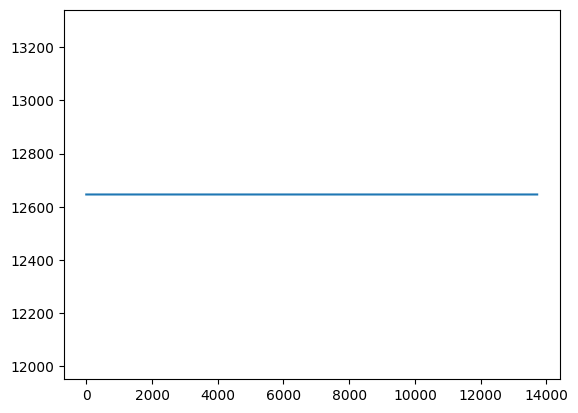

In [108]:
aux=[]
aux_volts=[]
x_axis=[]
unit_voltage=pd.DataFrame()
cont=0

for i in range (0,unit.shape[0]):
    l=len(unit.iloc[i,2])
    #print('Len=',l)
    if l<180:
        aux.append(int(unit.iloc[i,2][76:84],16))
        #aux_kmh.append((int(unit.iloc[i,2][68:76],16))*0.036)
        cont=cont+1     

unit_voltage['Voltage']=aux

for i in range(0,cont):
    x_axis.append(i)

plt.plot(x_axis,aux)